### ELO328 - Procesamiento Digital de Imágenes
# Clase 6: Cuantificación de color y seguimiento visual
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Quantization

Cuantificación (Quantization) significa restringir un conjunto continuo de valores a un conjunto discreto.

## Color quantization

Reduce el número de colores distintos utilizados en una imagen con el objetivo de mostrar imágenes con muchos colores en dispositivos que solo pueden mostrar una cantidad limitada de colores, generalmente debido a limitaciones de memoria, y permitir una compresión eficiente de ciertos tipos de imágenes.

<div align="center">
    <img src="img/quantization.png" alt="" width="50%" align="center" />
</div>

### Median Cut

 1. Mueva todos los píxeles a un solo cubo grande.
 2. Encuentre el canal de color (rojo, verde o azul) en la imagen con el mayor rango.
 3. Ordene los píxeles por los valores de ese canal.
 4. Encuentre la mediana y corte la región por ese píxel.
 5. Repita el proceso para ambos cubos hasta que tenga la cantidad deseada de colores.
 
<div align="center">
    <img src="img/flor.png" alt="" width="23%" align="left" />
    <img src="img/space.png" alt="" width="25%" align="center" />
</div>

In [1]:
import matplotlib.pyplot as plt
import numpy as np

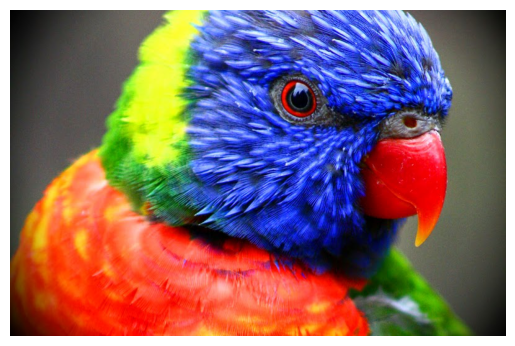

In [2]:
bird = plt.imread('img/bird.jpg')
plt.imshow(bird)
plt.axis('off')
plt.show()

In [3]:
from median_cut import plot_median_cut

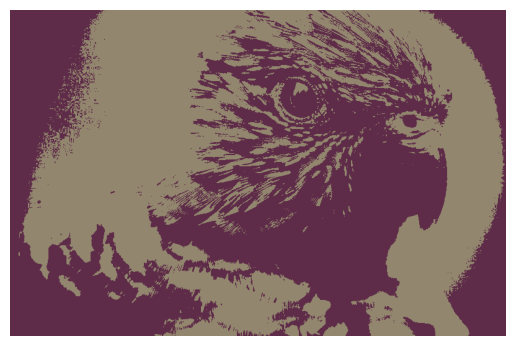

In [4]:
plot_median_cut(bird, 2)

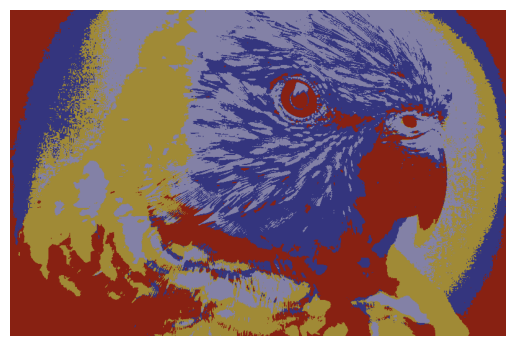

In [5]:
plot_median_cut(bird, 4)

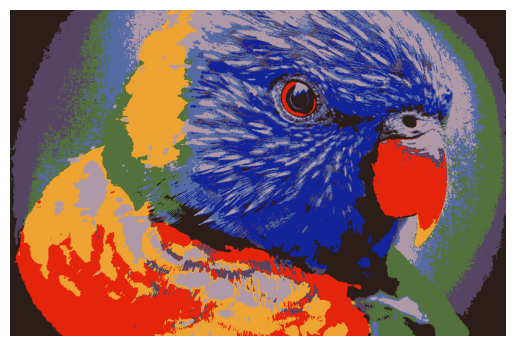

In [6]:
plot_median_cut(bird, 8)

# Mean shift

Técnica de análisis matemático para localizar los máximos de una función de densidad.

<div align="center">
    <img src="img/max-densidad.png" alt="" width="30%" align="center" />
</div>

# Mean Shift Algorithm

1. Inicializar una ventana.
2. Calcular el centro de masa de la ventana: $m(x) =  \frac{ \sum_{x_i \in \mathcal{N}(x)} K(x_i - x)x_i }{ \sum_{x_i \in \mathcal{N}(x)} K(x_i - x) }$, con $\mathcal{N}(x)$ vecindad de $x$.
3. Mover la ventana al centro de masa.
4. Repetir 2 y 3 hasta lograr convergencia.

<div align="center">
    <img src="img/meanshift.png" alt="" width="30%" align="left" />
    <img src="img/mean-shift.png" alt="" width="30%" align="center" />
</div>


## Kernel

La función $K(x_i - x)$ es un Kernel y determina el peso de los puntos cercanos para la reestimación de la media. Por lo general, se usa un kernel gaussiano $K(x_i - x) = e^{-\frac{\| x_i - x \|^2}{2\sigma^2}}$.


<div align="center">
    <img src="img/gaussian.jpg" alt="" width="25%" align="left" />
    <img src="img/gaussianKernel.jpg" alt="" width="20%" align="center" />
</div>

# Tracking

Mean shift se puede utilizar para el seguimiento visual (tracking). El algoritmo crea un mapa de confianza (función de densidad de probabilidad) en la nueva imagen basado en el histograma de color del objeto en la imagen anterior y usa el Mean shift vector para encontrar el peak del mapa cercano a la posición anterior del objeto.

<video controls src="img/tracking.mp4" />

In [7]:
import cv2 as cv

In [8]:
cap = cv.VideoCapture('img/boy-walking.mp4')
# take first frame of the video
ret, frame = cap.read()
# setup initial location of window
x, y, width, height = 0, 150, 100, 100
track_window = (x, y ,width, height)
# set up the ROI for tracking
roi = frame[y:y+height, x : x+width]
hsv_roi = cv.cvtColor(roi, cv.COLOR_BGR2HSV)
mask = cv.inRange(hsv_roi, np.array((0., 60., 32.)), np.array((180., 255., 255)))
roi_hist = cv.calcHist([hsv_roi], [0], mask, [180], [0, 180])
cv.normalize(roi_hist, roi_hist, 0, 255,cv.NORM_MINMAX)
# Setup the termination criteria, either 10 iteration or move by atleast 1 pt
term_crit = ( cv.TERM_CRITERIA_EPS | cv.TERM_CRITERIA_COUNT, 10, 1)

In [9]:
def plot_frame_roi(frame,roi):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 10))
    ax1.imshow(frame)
    ax1.set_title("First Frame")
    ax1.axis('off')
    ax2.imshow(roi)
    ax2.set_title("ROI")
    ax2.axis('off')
    plt.show()

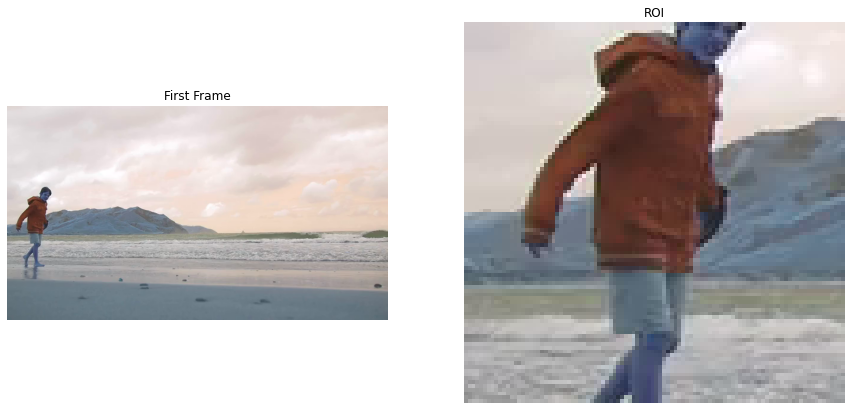

In [10]:
plot_frame_roi(frame,roi)

In [11]:
while(1):
    ret, frame = cap.read()
    if ret == True:

        hsv = cv.cvtColor(frame, cv.COLOR_BGR2HSV)
        dst = cv.calcBackProject([hsv], [0], roi_hist, [0, 180], 1)
        # apply meanshift to get the new location
        ret, track_window = cv.meanShift(dst, track_window, term_crit)
        # Draw it on image
        x,y,w,h = track_window
        final_image = cv.rectangle(frame, (x,y), (x+w, y+h), 255, 3)

        cv.imshow('dst', dst)
        cv.imshow('final_image',final_image)
        k = cv.waitKey(30) & 0xff
        if k == 27:
            break
    else:
        break

# close all opened windows
cv.destroyAllWindows()
cv.waitKey(1)

-1